In [59]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import math

import scipy
import random
import statistics
import umap as UM
from scipy.stats import zscore
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
import seaborn as sns
from IPython.display import clear_output
import muon

from joblib import Parallel, delayed

import sys
sys.path.append('/michorlab/bingxian/multi_modal_unpaired_matching/')
# from utils_MBTA import *
import utils_MBTA
import common_utils

import importlib
importlib.reload(utils_MBTA)
importlib.reload(common_utils)


''' 
embryo palette
'''
from matplotlib.colors import LinearSegmentedColormap

custom_colors2 = ["#b4213c", "#d8677f", "#d2a2ab", 
                  "#223f7f", "#3968b2", "#b3cecc", 
                  "#529b88", "#aac199", "#a5c07d"]  
custom_cmap2 = LinearSegmentedColormap.from_list("my_gradient", custom_colors2)



extracted_colors = [custom_cmap2(i / (7 - 1)) for i in range(7)]

embryo_palette = {'zygote': extracted_colors[0], 
                      '2cell':extracted_colors[1],
                      '4cell':extracted_colors[2], 
                      '8cell':extracted_colors[3], 
                      'morula':extracted_colors[4],
                      'E3.0':extracted_colors[5], 
                      'Blastocyst':extracted_colors[6],
                      'late blastocyst': 'black', 'early blastocyst': 'black'}

In [4]:
mod1 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h2az_sepClus.h5ad")
mod2 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k4me1_sepClus.h5ad")
mod3 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k4me3_sepClus.h5ad")
mod4 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k9me3_sepClus.h5ad")
mod5 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k27ac_sepClus.h5ad")
mod6 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k27me3_sepClus.h5ad")
mod7 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/h3k36me3_sepClus.h5ad")
mod8 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/embryo_scRNA.h5ad")
mod8.obs.cell_type = mod8.obs.cell_type.cat.add_categories(["Blastocyst"])
mod8.obs.cell_type = mod8.obs.cell_type.cat.add_categories(["E3.0"])

mod8.obs.cell_type[['early blastocyst' in i for i in mod8.obs.cell_type.values ]] = 'E3.0'
mod8.obs.cell_type[['late blastocyst' in i for i in mod8.obs.cell_type.values ]] = 'Blastocyst'

mod8.obs.cell_type = mod8.obs.cell_type.cat.remove_categories(["early blastocyst"])
mod8.obs.cell_type = mod8.obs.cell_type.cat.remove_categories(["late blastocyst"])

/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages

In [5]:
mod1.X = mod1.X.toarray() if hasattr(mod1.X, "toarray") else mod1.X
mod2.X = mod2.X.toarray() if hasattr(mod2.X, "toarray") else mod2.X  
mod3.X = mod3.X.toarray() if hasattr(mod3.X, "toarray") else mod3.X  
mod4.X = mod4.X.toarray() if hasattr(mod4.X, "toarray") else mod4.X
mod5.X = mod5.X.toarray() if hasattr(mod5.X, "toarray") else mod5.X   
mod6.X = mod6.X.toarray() if hasattr(mod6.X, "toarray") else mod6.X   
mod7.X = mod7.X.toarray() if hasattr(mod7.X, "toarray") else mod7.X



mod1_tensor = torch.tensor(mod1.X).type(torch.float32)
mod2_tensor = torch.tensor(mod2.X).type(torch.float32)
mod3_tensor = torch.tensor(mod3.X).type(torch.float32)
mod4_tensor = torch.tensor(mod4.X).type(torch.float32)
mod5_tensor = torch.tensor(mod5.X).type(torch.float32)
mod6_tensor = torch.tensor(mod6.X).type(torch.float32)
mod7_tensor = torch.tensor(mod7.X).type(torch.float32)
mod8_tensor = torch.tensor(zscore(mod8.X)).type(torch.float32)

In [6]:

def run_training(name, tensor):
    print(f'start {name}')
    torch.set_num_threads(2)
    model = utils_MBTA.train_model(
        tensor,
        Nnodes=200,
        latent_dim=20,
        batchSize=150,
        Ndir=50,
        Niter=20000,
        balance=False
    )
    print(f"done with {name}")
    return name, model

# construct all modality dictionaries for parallel training of the VAE component
all_modalities = {'h2az': mod1_tensor,
                  'h3k4me1': mod2_tensor,
                  'h3k4me3': mod3_tensor,
                  'h3k9me3': mod4_tensor,
                  'h3k27ac': mod5_tensor,
                  'h3k27me3': mod6_tensor,
                  'h3k36me3': mod7_tensor,
                  'RNA': mod8_tensor}



results = Parallel(n_jobs=10)(
    delayed(run_training)(name, tensor) for name, tensor in all_modalities.items()
)



start h3k4me1
start RNA
start h3k27ac
start h3k9me3
start h3k36me3
start h2az
start h3k4me3
start h3k27me3
Iter: 0, loss_re: 1002.2824, loss_pcf: 0.0000
reconstruction loss = 452.44324
Iter: 0, loss_re: 1614.0919, loss_pcf: 0.0000
Iter: 0, loss_re: 2711.4773, loss_pcf: 0.0000
reconstruction loss = 1025.0454
Iter: 0, loss_re: 5825.2632, loss_pcf: 0.0000
reconstruction loss = 2142.778
Iter: 0, loss_re: 3334.1021, loss_pcf: 0.0000
Iter: 0, loss_re: 3169.8005, loss_pcf: 0.0000
reconstruction loss = 5273.0723
Iter: 0, loss_re: 1942.1667, loss_pcf: 0.0000
Iter: 0, loss_re: 2766.9739, loss_pcf: 0.0000
reconstruction loss = 2775.6091
reconstruction loss = 2612.0242
reconstruction loss = 1390.0663
reconstruction loss = 2223.5579
Iter: 1000, loss_re: 427.1854, loss_pcf: 0.0000
reconstruction loss = 270.80737
Iter: 2000, loss_re: 357.5082, loss_pcf: 0.0000
reconstruction loss = 186.83946
Iter: 3000, loss_re: 283.4825, loss_pcf: 0.0000
reconstruction loss = 129.56245
Iter: 4000, loss_re: 255.0569,

In [7]:
''' 
create a MBTA object from trained models
'''

models = []
for modality_name, model in results:
    models.append(utils_MBTA.MBTA_submodule(model, "MBTA", modality_name))

MBTA = utils_MBTA.general_MBTA()

for i in models:
    MBTA.add_model(i, i.modality_name)

print(dir(MBTA))

class created
['RNA', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', 'add_model', 'coarse_training', 'generate', 'h2az', 'h3k27ac', 'h3k27me3', 'h3k36me3', 'h3k4me1', 'h3k4me3', 'h3k9me3', 'paired_training']


In [10]:
''' 
parallel training of the flow matching component
'''
# from mod1 to mod2 
def run_FMs(mod1, mod1_name, mod2, mod2_name, mod1_label, mod2_label):
    print(f"start training model that goes from {mod1_name} to {mod2_name}")
    MBTA.coarse_training(mod1, mod1_name,
                         mod2, mod2_name,
                         mod1_label, mod2_label,
                         Nitr=100000
                         )
    

all_pairs = [(mod8_tensor, 'RNA', mod1_tensor, 'h2az', mod8.obs.cell_type.values, mod1.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod2_tensor, 'h3k4me1', mod8.obs.cell_type.values, mod2.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod3_tensor, 'h3k4me3', mod8.obs.cell_type.values, mod3.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod4_tensor, 'h3k9me3', mod8.obs.cell_type.values, mod4.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod5_tensor, 'h3k27ac', mod8.obs.cell_type.values, mod5.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod6_tensor, 'h3k27me3', mod8.obs.cell_type.values, mod6.obs.cell_type.values),
             (mod8_tensor, 'RNA', mod7_tensor, 'h3k36me3', mod8.obs.cell_type.values, mod7.obs.cell_type.values)]






results = Parallel(n_jobs=8, backend='threading')(
    delayed(run_FMs)(mod1, mod1_name, mod2, mod2_name, mod1_label, mod2_label) for mod1, mod1_name, mod2, mod2_name, mod1_label, mod2_label in all_pairs
)





start training model that goes from RNA to h3k4me1
start training model that goes from RNA to h3k4me3
start training model that goes from RNA to h2az
start training model that goes from RNA to h3k27me3
start training model that goes from RNA to h3k27ac
start training model that goes from RNA to h3k9me3
start training model that goes from RNA to h3k36me3
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
0
0
0
0
0
0
0
1000
1000
1000
1000
1000
1000
1000
2000
2000
2000
2000
2000
2000
2000
3000
3000
3000
3000
3000
3000
3000
4000
4000
4000
4000
4000
4000
4000
5000
5000
5000
5000
5000
5000
5000
6000
6000
6000
6000
6000
6000
6000
7000
7000
7000
7000
7000
700

In [12]:
input = mod8_tensor.clone()


translated_h2az, low1 = MBTA.generate(input, 'RNA',
                  mod1_tensor[0].repeat((input.shape[0], 1)), 'h2az', get_low = True)

translated_h3k4me1, low2 = MBTA.generate(input, 'RNA',
                  mod2_tensor[0].repeat((input.shape[0], 1)), 'h3k4me1', get_low = True)

translated_h3k4me3, low3 = MBTA.generate(input, 'RNA',
                  mod3_tensor[0].repeat((input.shape[0], 1)), 'h3k4me3', get_low = True)

translated_h3k9me3, low4 = MBTA.generate(input, 'RNA',
                  mod4_tensor[0].repeat((input.shape[0], 1)), 'h3k9me3', get_low = True)

translated_h3k27ac, low5 = MBTA.generate(input, 'RNA',
                  mod5_tensor[0].repeat((input.shape[0], 1)), 'h3k27ac', get_low = True)

translated_h3k27me3, low6 = MBTA.generate(input, 'RNA',
                  mod6_tensor[0].repeat((input.shape[0], 1)), 'h3k27me3', get_low = True)

translated_h3k36me3, low7 = MBTA.generate(input, 'RNA',
                  mod7_tensor[0].repeat((input.shape[0], 1)), 'h3k36me3', get_low = True)

done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])
done generating source and target
torch.Size([939, 20])


In [52]:


pca_low = PCA(n_components = 20, random_state = 1)
reducer2 = UM.UMAP(n_neighbors=50, 
                  metric = 'euclidean', 
                  repulsion_strength=.1, 
                  n_epochs=500, 
                  negative_sample_rate=5, 
                  min_dist = .5,
                  verbose = False,
                  random_state=1,
                  n_components = 2
                 )




In [53]:
mod2

AnnData object with n_obs × n_vars = 392 × 18000
    obs: 'nCount_peaks', 'nFeature_peaks', 'seurat_clusters', 'group.ident', 'cell_type'
    var: 'n_cells', 'n_counts'
    uns: 'rank_genes_groups'

In [54]:
# l1 = reducer2.fit_transform(low1.detach().numpy())
l1 = reducer2.fit_transform(pca_low.fit_transform(translated_h2az))
l2 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k4me1))
l3 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k4me3))
l4 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k9me3))
l5 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k27ac))
l6 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k27me3))
l7 = reducer2.fit_transform(pca_low.fit_transform(translated_h3k36me3))


/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [50]:
all_low = {'translated_h2az': l1,
           'translated_h3k4me1':l2,
           'translated_h3k4me3':l3,
           'translated_h3k9me3':l4,
           'translated_h3k27ac':l5,
           'translated_h3k27me3': l6,
           'translated_h3k36me3':l7}


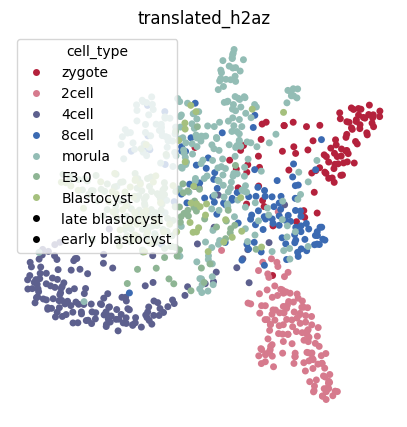

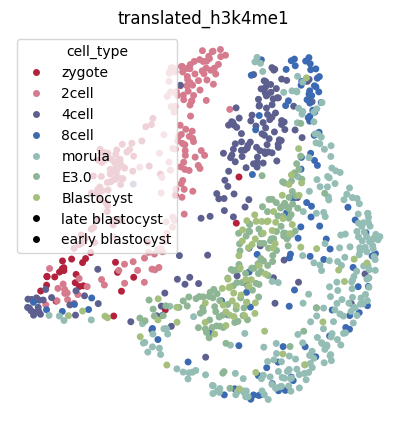

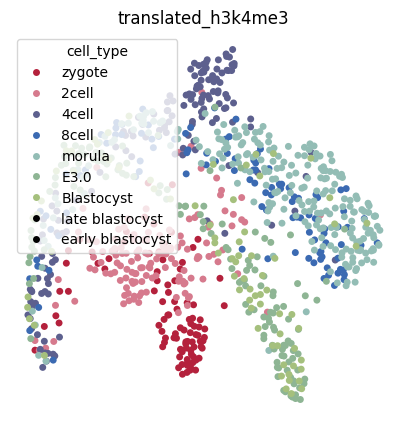

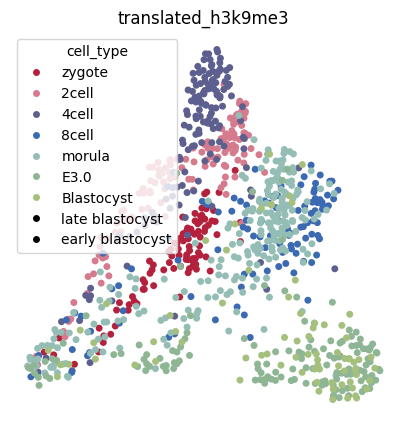

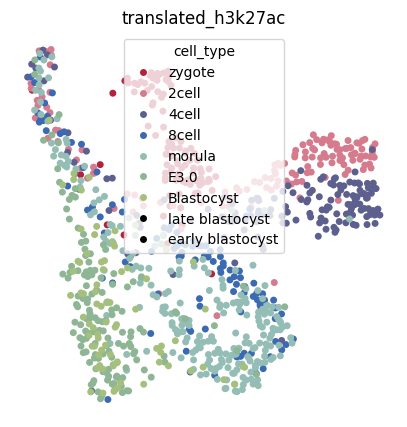

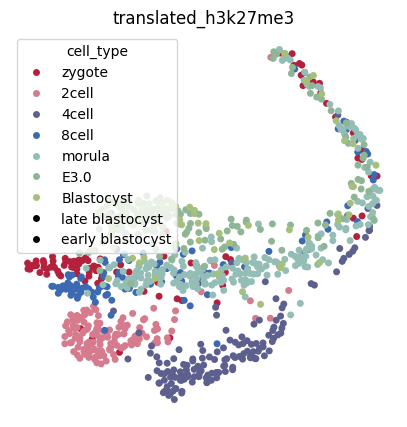

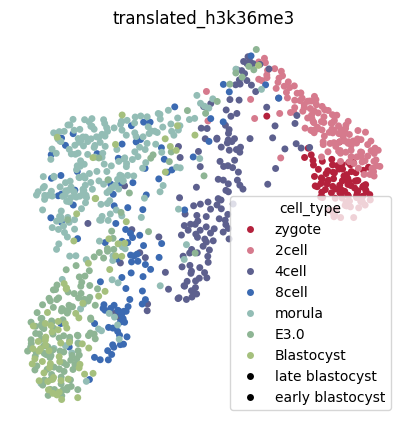

In [56]:
for i in all_low.keys():
    use_l = all_low[i]

    sns.scatterplot(x = use_l[:,0], y =use_l[:,1], hue = mod8.obs.cell_type, linewidth = 0, s = 25, alpha = 1, palette = embryo_palette,  hue_order = embryo_palette.keys(),
                legend = True)
    plt.gcf().set_size_inches(5,5)
    plt.axis('off')
    plt.title(i)
    plt.show()


In [70]:
importlib.reload(common_utils)


df1 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h2az.predict(mod1_tensor), mod1_tensor.detach().numpy(),translated_h2az)
df2 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k4me1.predict(mod2_tensor), mod2_tensor.detach().numpy(),translated_h3k4me1)
df3 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k4me3.predict(mod3_tensor), mod3_tensor.detach().numpy(),translated_h3k4me3)
df4 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k9me3.predict(mod4_tensor), mod4_tensor.detach().numpy(),translated_h3k9me3)
df5 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k27ac.predict(mod5_tensor), mod5_tensor.detach().numpy(),translated_h3k27ac)
df6 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k27me3.predict(mod6_tensor), mod6_tensor.detach().numpy(),translated_h3k27me3)
df7 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.h3k36me3.predict(mod7_tensor), mod7_tensor.detach().numpy(),translated_h3k36me3)



In [71]:
all_low = {'translated_h2az': df1,
           'translated_h3k4me1':df2,
           'translated_h3k4me3':df3,
           'translated_h3k9me3':df4,
           'translated_h3k27ac':df5,
           'translated_h3k27me3': df6,
           'translated_h3k36me3':df7}




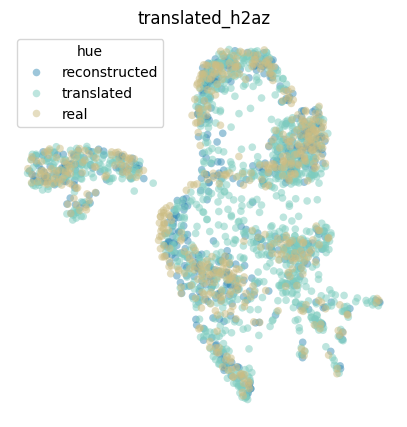

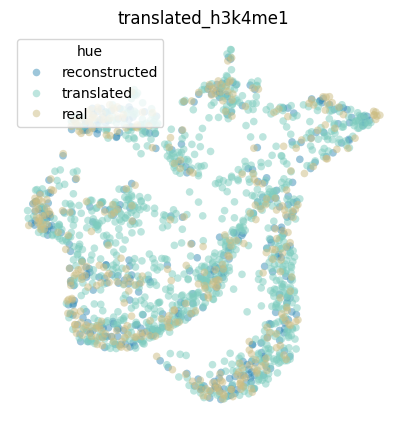

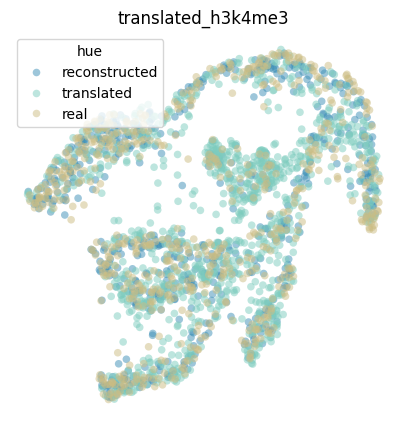

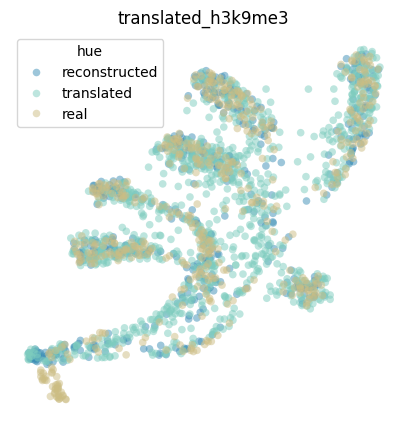

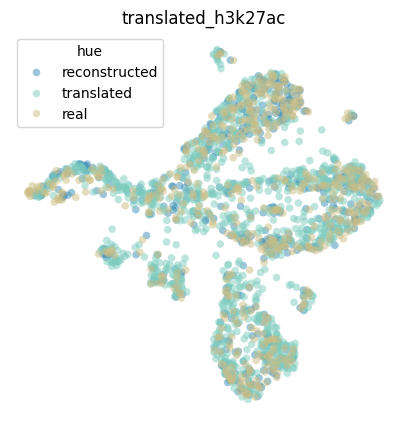

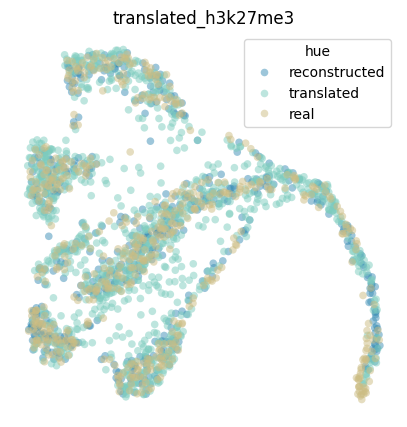

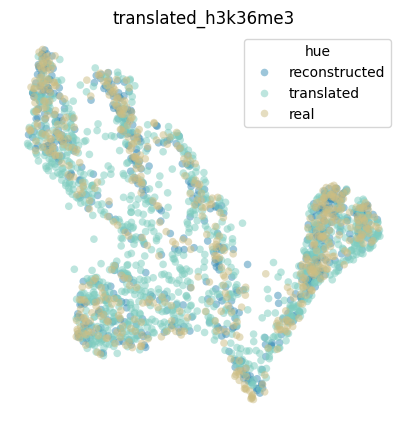

In [73]:
recon_palette = {'reconstructed':"#3c8fb6", 
                 'translated': '#7dccbe',
                 'real': "#ccbd83" }

recon_palette2 = {'reconstructed':"#4d65a8", 
                 'translated': '#6e8fc2',
                 'real': "#c2b43a" }

for i in all_low.keys():
    df1 = all_low[i]

# coembedding of real, reconstructed and translated protein
    sns.scatterplot(df1, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 30, alpha = .5,  palette= recon_palette, legend = True)
    plt.gcf().set_size_inches(5,5)
    plt.axis('off')
    plt.title(i)
    plt.show()